In [1]:
import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1) 
import matplotlib.pyplot as plt
import sys
sys.path.append('/suphys/aani0116/Work/neutronstar_minicluster/my_modules')
import numpy as np
from scipy.stats import uniform_direction
from mc_declare import *
from scipy.interpolate import interp1d
pot_mw = agama.Potential('/suphys/aani0116/minicluster/minicluster_tidal/Agama/data/McMillan17.ini')
from reverse_orbit import reverse_orbit,reverse_orbit_multiple
from mass_loss_new import *
from N_calculator import N_encounter 
from N_calculator import stellar_rho_total
from hmf import *
from mc_xv import generate_xv_at,generate_xv
from scipy.integrate import quad
from scipy.interpolate import interp1d
from hmf_new import *
from times import dynamical_time

In [26]:
N_mc=100
mc_masses=np.ones(N_mc)*1e-10


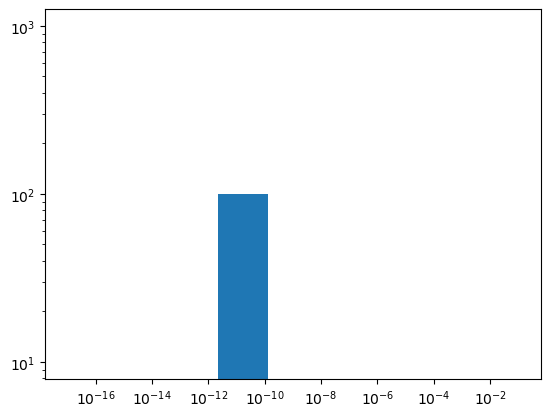

In [27]:
plt.hist(mc_masses,bins=np.logspace(-17,-1,10))
plt.xscale('log')
plt.yscale('log')

In [16]:
pos_final=np.array([3.0,0.1,0.1]) 
simulation_time = 10               
tupd = 1e-1       


In [17]:
mc = [Minicluster(mass=m, delta=5, concentration=10) for m in mc_masses] #three free parameters, mass, concentration and delta
mc_radiuses=np.array([mc[i].radius for i in range(N_mc)])
mc_fc=generate_xv_at(pos_final,N_mc)# initial conditions radnomyl generated, which is velocity in this case
mc_ic=reverse_orbit_multiple(mc_fc,pot_mw,simulation_time,0)#recerse integrated to find where they start

100 orbits complete (113.1 orbits/s)


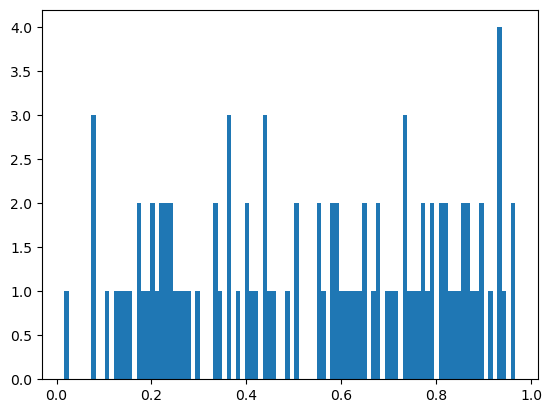

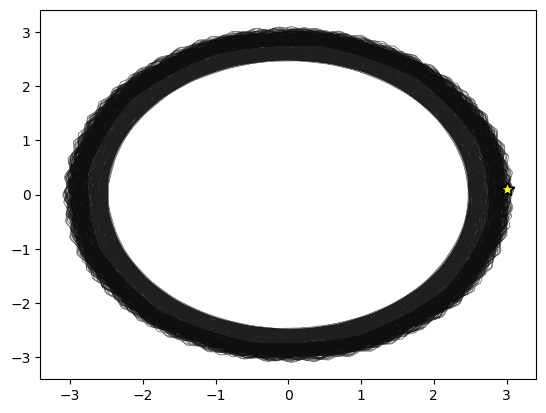

In [18]:

orbit = np.vstack(agama.orbit(ic=mc_ic, potential=pot_mw, time=simulation_time, timestart=0, trajsize=1000, accuracy=1e-10, verbose=False))
time_f = np.stack(orbit[:, 0])
pos_f = np.stack(orbit[:, 1])
r_all = np.sqrt(pos_f[:, :, 0]**2 + pos_f[:, :, 1]**2 + pos_f[:, :, 2]**2)
r_peri = np.min(r_all, axis=1)  
r_apo  = np.max(r_all, axis=1)  

eccentricity = (r_apo - r_peri) / (r_apo + r_peri)  

plt.hist(eccentricity,bins=100)
plt.show()

a,b=0,1
ecc_mask = eccentricity <0.1

for i in np.where(ecc_mask)[0]:
    line, = plt.plot(pos_f[i][:, a], pos_f[i][:, b], alpha=0.5, color='k', lw=0.7)
    plt.plot(pos_f[i][-1, a], pos_f[i][-1, b], '*', color='Yellow',
              markersize=10, markeredgecolor='k')


In [19]:
def stellar_energy(N,M,R,v,its_sum):
    b = np.sqrt(np.random.uniform(0, (1e-3)**2, N))
    #b=np.random.uniform(1000*R, (1e-4), N)
    E=((4*0.33*agama.G*agama.G*M*0.27*R*R)/((b**4)*(v**2)))
    E_sum=np.sum(E)
    E_rms_sum=np.sum(np.sqrt(E))**2
    if its_sum:
        return E_sum
    else:
        return E_rms_sum

In [20]:
def N_encounter_new(t,xv, b_max=1e-3):
    return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)

In [21]:
def N_encounter_multiple(t, xv, b_max=1e-3): #Give time array to intergate
    rho   = stellar_rho_total(xv[..., 0], xv[..., 1], xv[..., 2])   # (..., n_time)
    speed = np.linalg.norm(xv[..., 3:], axis=-1)                    # (..., n_time)
    return np.trapezoid(rho * speed * np.pi * b_max**2, t, axis=-1)


In [22]:
kappa=3.54
beta=3.47
binding_energy = lambda mass, radius: beta * agama.G * mass**2 / radius
total_energy = lambda Eb: (kappa/2-beta) * Eb/beta


In [23]:
def stellar_energy_array(N, M, R, V, its_sum=True):
    N, M, R, V = np.asarray(N), np.asarray(M), np.asarray(R), np.asarray(V)
    its_sum = np.broadcast_to(its_sum, N.shape)   # lets you pass one bool for all, or an array

    return np.array([
        stellar_energy(n, m, r, v, s)
        for n, m, r, v, s in zip(N, M, R, V, its_sum)
    ])


In [24]:
time_i=0
masses_array=[mc_masses]
radiuses_array=[mc_radiuses]
time_array=[time_i]
N_encounter_array=[np.ones_like(mc_masses)*0]

while time_i < simulation_time-0.5*tupd:

    orbit = np.vstack(agama.orbit(ic=mc_ic, potential=pot_mw, time=tupd,timestart=time_i, trajsize=3, accuracy=1e-14,verbose=False))
    time=np.stack(orbit[:,0])
    pos=np.stack(orbit[:,1])
    v_avg=np.mean((np.linalg.norm(pos[:,:,3:],axis=-1)),axis=1)

    N_encounter_with_star=N_encounter_multiple(time, pos,b_max=0.001)

    col_time=tupd/N_encounter_with_star
    its_sum=col_time<dynamical_time(mc_masses,mc_radiuses)
    delE=stellar_energy_array(N_encounter_with_star.astype(int),mc_masses,mc_radiuses,v_avg,its_sum)    
    
    Eb=binding_energy(mc_masses,mc_radiuses)
    Ei=total_energy(Eb)

    delEbyE=abs(delE/Eb)
    
    mass_loss=mc_masses*get_dm_frac(delEbyE)

    
    
        

    Ef=Ei+(1-get_fej(delEbyE))*delE-get_fub(delEbyE)*Ei
    alive = (get_dm_frac(delEbyE) < 1) & (mass_loss < mc_masses) & (mc_masses!=0) & (Ef<0)

    
    
    mc_masses=np.where(alive,mc_masses-mass_loss,0)

    mc_radiuses = np.where((N_encounter_with_star > 1),
                    (kappa/2 - beta) * agama.G * mc_masses * mc_masses / Ef,
                    mc_radiuses)
    mc_radiuses=np.where(alive,mc_radiuses,0)




    masses_array.append(mc_masses)
    radiuses_array.append(mc_radiuses)
    time_array.append(time[0][-1])
    N_encounter_array.append(N_encounter_with_star)
    
    mc_ic=pos[:,-1]
    time_i += tupd
    print(time_i)
    if time_i % (simulation_time/20) < tupd: print(time_i)
masses_array=np.array(masses_array)
radiuses_array=np.array(radiuses_array)
time_array=np.array(time_array)
N_encounter_array=np.array(N_encounter_array)
print('Survival fraction:',alive.sum()/N_mc)

KeyboardInterrupt: 

In [ ]:
#np.savez('mc_r_1e-10_small.npz',
         masses=masses_array,
         radiuses=radiuses_array)


In [40]:
masses_array[-1].mean()/masses_array[0].mean()

np.float64(0.4391821710989293)

In [41]:
masses_array[-1].mean()

np.float64(4.3918217109892916e-11)

In [42]:
masses_array[0].mean()

np.float64(9.999999999999996e-11)

In [20]:
masses_array[-1].mean()/masses_array[0].mean()

np.float64(0.46429529938312275)

In [21]:
masses_array[-1].mean()

np.float64(4.6429529938312284e-11)

In [22]:
masses_array[0].mean()

np.float64(1.0000000000000002e-10)

In [ ]:
/suphys/aani0116/Work/neutronstar_minicluster/hpc_run/8kpc/mc_.npz,
            

In [12]:
import numpy as np
data = np.load('mc_r_1e-10.npz')
data.files               # ['masses', 'radiuses']

masses_array = data['masses']
radiuses_array = data['radiuses']
print(masses_array.shape)


(1001, 1000)


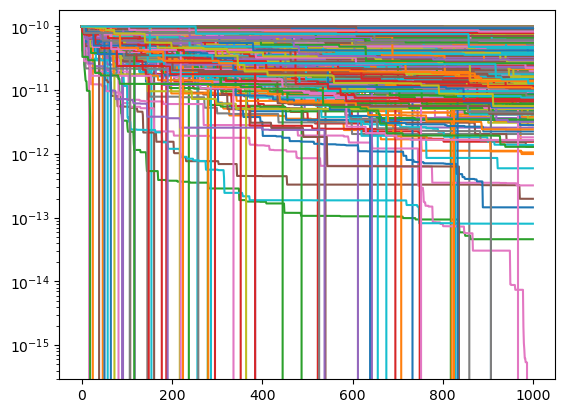

In [13]:
import matplotlib.pyplot as plt
plt.plot(masses_array)
plt.yscale('log')

In [22]:
a=np.array(masses_array)

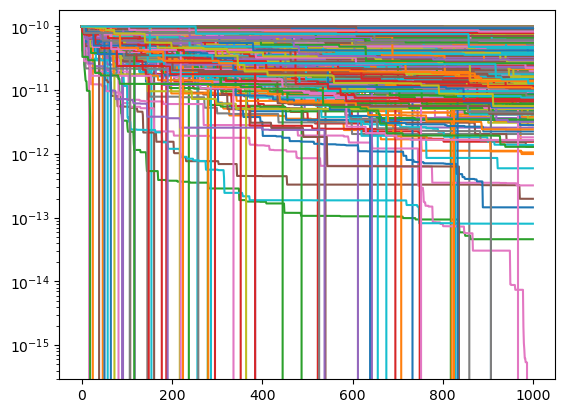

In [31]:
for i in range(1000):
    plt.plot(a[:,i])
    plt.yscale('log')